# 02 · Hotel KPIs: cancellations, prices and seasonality

**Question:** how often are bookings cancelled, at what price are rooms sold, how do both change through the year, and how much revenue do cancellations cost? Resort and city hotel are compared throughout.

**Data:** clean file from notebook 01 (119,208 bookings).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/processed/hotel_bookings_clean.csv", parse_dates=["arrival_date"])

MONTHS = ["January", "February", "March", "April", "May", "June",
          "July", "August", "September", "October", "November", "December"]
COLORS = {"City Hotel": "#2a78d6", "Resort Hotel": "#eb6834"}

print(df.shape)

(119208, 36)


## 2.1 Headline KPIs by hotel
For each hotel: number of bookings, cancellation rate (%), ADR and revenue lost to cancellations.

**ADR (Average Daily Rate)** as hotels compute it: room revenue ÷ room-nights sold, using only stays that happened (not cancelled) with `adr` > 0.

In [2]:
# Bookings and cancellation rate
kpi = df.groupby("hotel").agg(
    n_bookings=("is_canceled", "size"),
    cancel_rate=("is_canceled", "mean"),
)
kpi["cancel_rate"] = (kpi["cancel_rate"] * 100).round(1)

# ADR: only stays that happened, with a price and at least 1 night
stays = df[(df["is_canceled"] == 0) & (df["adr"] > 0) & (df["total_nights"] > 0)]
kpi["adr"] = (stays.groupby("hotel")["revenue"].sum()
              / stays.groupby("hotel")["total_nights"].sum()).round(1)

# Revenue lost to cancellations
kpi["revenue_lost"] = df[df["is_canceled"] == 1].groupby("hotel")["revenue"].sum().round(0)

kpi

,n_bookings,cancel_rate,adr,revenue_lost
hotel,,,,
City Hotel,79162,41.8,108.0,10879660.0
Resort Hotel,40046,27.8,97.6,5842177.0


City Hotel: 66% of bookings, cancellation rate 41.8% (1.5x the Resort’s 27.8%), ADR 108.0 vs 97.6. Cancelled bookings represent ~16.7M of potential revenue over 26 months (10.9M City, 5.8M Resort): an upper bound, since some rooms are resold and some deposits are kept. Currency not stated (likely EUR).

## 2.2 Cancellation rate by month
Cancellation rate (%) by arrival month and hotel. Save as `cancel_month` with columns `arrival_date_month`, `hotel`, `cancel_rate`.

In [3]:
cancel_month = (
    df.groupby(['arrival_date_month','hotel'])['is_canceled']
    .mean()
    .mul(100)
    .round(1)
    .rename("cancel_rate")
    .reset_index()
)

cancel_month

,arrival_date_month,hotel,cancel_rate
0,April,City Hotel,46.3
1,April,Resort Hotel,29.3
2,August,City Hotel,40.1
3,August,Resort Hotel,33.4
4,December,City Hotel,42.2
5,December,Resort Hotel,23.9
6,February,City Hotel,38.4
7,February,Resort Hotel,25.6
8,January,City Hotel,39.7
9,January,Resort Hotel,14.8


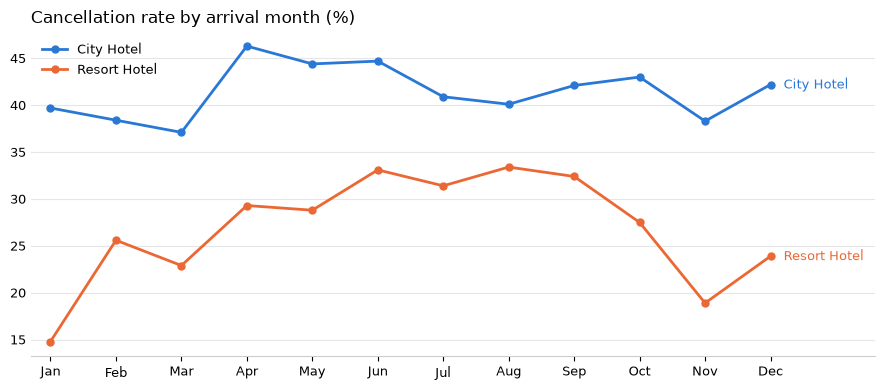

In [4]:
def plot_by_month(data, value, title, fname, fmt="{:.0f}%"):
    fig, ax = plt.subplots(figsize=(9, 4))
    for hotel, color in COLORS.items():
        s = (data[data["hotel"] == hotel]
             .set_index("arrival_date_month")[value]
             .reindex(MONTHS))
        ax.plot(range(12), s.values, color=color, linewidth=2, marker="o", markersize=5, label=hotel)
        ax.text(11.2, s.values[-1], hotel, color=color, va="center", fontsize=9)
    ax.set_xticks(range(12))
    ax.set_xticklabels([m[:3] for m in MONTHS], fontsize=9)
    ax.grid(axis="y", color="#e6e6e6", linewidth=0.8)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color("#ccc")
    ax.tick_params(axis="y", length=0, labelsize=9)
    ax.set_xlim(-0.3, 12.6)
    ax.legend(frameon=False, loc="upper left", fontsize=9)
    ax.set_title(title, loc="left", fontsize=12)
    plt.tight_layout()
    plt.savefig(f"../figures/{fname}", dpi=150, bbox_inches="tight")
    plt.show()

plot_by_month(cancel_month, "cancel_rate", "Cancellation rate by arrival month (%)", "cancel_rate_by_month.png")

City Hotel cancellations are high all year (37–46%, peak in April–June). Resort cancellations are seasonal: from 14.8% in January to 33–34% in June–August. The gap between the two hotels is largest in winter (~25 points in January) and smallest in summer (~7 points in August).

## 2.3 ADR by month
ADR by arrival month and hotel (same definition as 2.1). Save as `adr_month` with columns `arrival_date_month`, `hotel`, `adr`.

In [5]:
g = stays.groupby(['arrival_date_month', 'hotel'])

adr_month = (
    (g['revenue'].sum() / g['total_nights'].sum())
    .round(1)
    .rename('adr')
    .reset_index()
)

adr_month

,arrival_date_month,hotel,adr
0,April,City Hotel,113.5
1,April,Resort Hotel,76.5
2,August,City Hotel,118.8
3,August,Resort Hotel,174.9
4,December,City Hotel,92.4
5,December,Resort Hotel,72.9
6,February,City Hotel,88.4
7,February,Resort Hotel,54.8
8,January,City Hotel,85.4
9,January,Resort Hotel,50.1


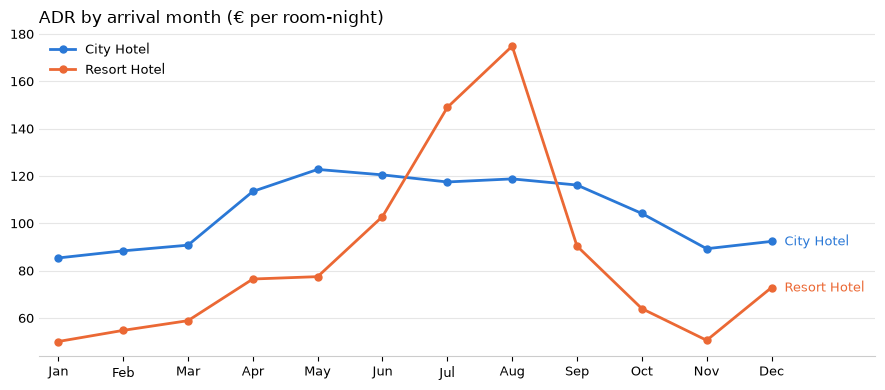

In [6]:
plot_by_month(adr_month, "adr", "ADR by arrival month (€ per room-night)", "adr_by_month.png")

Resort prices are highly seasonal: ADR from 50.1 in January to 174.9 in August (3.5x); the City Hotel ranges from 85.4 to 122.8 (1.4x) and peaks in May–June. In both hotels cancellations are highest when prices are highest (Resort in summer, City in spring), so revenue at risk is concentrated in peak season.

## 2.4 Lead time
`lead_time` = days between booking and arrival. Group it into buckets and compute the cancellation rate of each.

| Bucket | Days |
|---|---|
| 1. Last minute | 0–7 |
| 2. 1–4 weeks | 8–30 |
| 3. 1–3 months | 31–90 |
| 4. 3–6 months | 91–180 |
| 5. 6–12 months | 181–365 |
| 6. Over 1 year | 366+ |

In [7]:
bins = [-1, 7, 30, 90, 180, 365, df["lead_time"].max()]
labels = ["1. 0-7 days", "2. 8-30 days", "3. 1-3 months",
          "4. 3-6 months", "5. 6-12 months", "6. Over 1 year"]

df["lead_bucket"] = pd.cut(df["lead_time"], bins=bins, labels=labels)

lead = (
    df.groupby("lead_bucket", observed=True)
      .agg(n_bookings=("is_canceled", "size"),
           cancel_rate=("is_canceled", "mean"))
)
lead["cancel_rate"] = (lead["cancel_rate"] * 100).round(1)
lead

,n_bookings,cancel_rate
lead_bucket,,
1. 0-7 days,19635,9.6
2. 8-30 days,18945,27.9
3. 1-3 months,29528,37.7
4. 3-6 months,26420,44.7
5. 6-12 months,21533,55.5
6. Over 1 year,3147,67.7


Lead time is the strongest signal so far: the cancellation rate rises at every step, from 9.6% for bookings made within 7 days of arrival to 55.5% at 6–12 months and 67.7% over 1 year (7x). This also explains the Resort’s summer peak, since summer holidays are booked months ahead.

## 2.5 Deposit type
Cancellation rate by `deposit_type`. Is there anything surprising? If so, look at who makes those bookings (`market_segment`, `is_duplicate`).

In [8]:
dep = df.groupby('deposit_type').agg(
    n_bookings = ('is_canceled','size'),
    cancel_rate = ('is_canceled', 'mean')
)

dep['cancel_rate'] = (dep['cancel_rate'] * 100).round(1)
dep

,n_bookings,cancel_rate
deposit_type,,
No Deposit,104460,28.4
Non Refund,14586,99.4
Refundable,162,22.2


In [9]:
nr = df[df["deposit_type"] == "Non Refund"]
print(nr["hotel"].value_counts(normalize=True).round(3), "\n")
print(nr["market_segment"].value_counts(normalize=True).round(3), "\n")
print(f"Share of duplicated rows: {nr['is_duplicate'].mean():.1%}")
print(f"Average lead time: {nr['lead_time'].mean():.0f} days vs {df['lead_time'].mean():.0f} overall")

hotel
City Hotel      0.882
Resort Hotel    0.118
Name: proportion, dtype: float64 

market_segment
Groups           0.629
Offline TA/TO    0.343
Corporate        0.023
Online TA        0.004
Direct           0.001
Name: proportion, dtype: float64 

Share of duplicated rows: 98.1%
Average lead time: 213 days vs 104 overall


In [10]:
no_nr = df[df["deposit_type"] != "Non Refund"]
(no_nr.groupby("hotel")["is_canceled"].mean() * 100).round(1)

hotel
City Hotel      30.5
Resort Hotel    24.7
Name: is_canceled, dtype: float64

Counterintuitive: “Non Refund” bookings (14,586) are cancelled 99.4% of the time vs 28.4% without deposit. They are almost all group/tour-operator room blocks (97% Groups or Offline TA/TO, 98.1% duplicated rows, 88% City Hotel) booked ~213 days ahead. The label likely reflects contract terms of the block, or a coding issue in the source. If deposits were kept, these cancellations overstate revenue lost. Excluding them, the cancellation rate drops from 41.8% to 30.5% for the City Hotel and from 27.8% to 24.7% for the Resort: the gap between the two hotels shrinks from 14 to 6 points.

## 2.6 Other signals
Cancellation rate by `market_segment`, by `is_repeated_guest` and by `total_of_special_requests`.

In [11]:
for col in ["market_segment", "is_repeated_guest", "total_of_special_requests"]:
    t = df.groupby(col).agg(
        n_bookings=("is_canceled", "size"),
        cancel_rate=("is_canceled", "mean"),
    )
    t["cancel_rate"] = (t["cancel_rate"] * 100).round(1)
    display(t.sort_values("cancel_rate", ascending=False))

,n_bookings,cancel_rate
market_segment,,
Undefined,2,100.0
Groups,19790,61.1
Online TA,56408,36.8
Offline TA/TO,24181,34.3
Aviation,235,22.1
Corporate,5282,18.8
Direct,12582,15.4
Complementary,728,12.2


,n_bookings,cancel_rate
is_repeated_guest,,
0,115454,37.8
1,3754,14.7


,n_bookings,cancel_rate
total_of_special_requests,,
0,70199,47.8
2,12952,22.1
1,33183,22.0
3,2494,17.8
4,340,10.6
5,40,5.0


## Findings

**1. The City Hotel has the bigger cancellation problem, but a quarter of it comes from group blocks.**
The City Hotel has 66% of bookings and a cancellation rate of 41.8% vs 27.8% for the Resort. Excluding "Non Refund" bookings (almost all tour-operator and group room blocks, cancelled 99.4% of the time), the rates drop to 30.5% and 24.7%: the gap shrinks from 14 to 6 points.

**2. Cancellations are highest when rooms are most expensive.**
Resort prices are highly seasonal (ADR from 50.1 in January to 174.9 in August, 3.5x) and its cancellations follow the same curve (from 14.8% in January to 33–34% in summer). The City Hotel peaks in spring for both prices and cancellations. Revenue at risk is concentrated in peak season.

**3. Lead time is the strongest single signal.**
The cancellation rate rises at every step, from 9.6% for bookings made within 7 days of arrival to 67.7% for bookings made more than a year ahead.

**4. Commitment signals go with fewer cancellations.**
Direct bookings (15.4%) cancel 2.4x less than online travel agency bookings (36.8%); repeat guests (14.7%) 2.6x less than new guests (37.8%); guests with at least one special request ~22% vs 47.8% with none.

**Revenue at stake:** cancelled bookings represent ~16.7M of potential revenue over 26 months (10.9M City, 5.8M Resort). This is an upper bound: some rooms are resold, and Non Refund deposits may have been kept.

**Caveats:** correlations, not causes; only 2016 is a full year; currency not stated (likely EUR).